# Car Breakdown Prediction

## Artificial Intelligence Project

In this notebook we analyse the training data and build a first machine learning model to predict whether a car will break down within the next 30 days.

The notebook contains:
- Exploratory Data Analysis (EDA)
- Data preparation
- Random Forest baseline model
- Model evaluation
- Predictions on the test set
- Submission file creation
- GenAI section

In [225]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## Load the training data

We start by loading the training dataset.  
This dataset contains the features and the target variable `breakdown_next_30_days`.

## Dataset overview

We first inspect the shape of the dataset, the column names and the data types.
This gives us a first understanding of the available information.

In [226]:
train = pd.read_csv("../train_CarBreakDown.csv")
print("Shape of dataset:", train.shape)
print()

print("Column names:")
print(train.columns)
print()

print("Data types:")
print(train.dtypes)

Shape of dataset: (1050, 14)

Column names:
Index(['id', 'vehicle_brand', 'vehicle_age_years', 'mileage_km',
       'engine_hours', 'last_service_km_ago', 'oil_quality_pct',
       'avg_trip_length_km', 'weather_exposure', 'fuel_type',
       'cleanliness_score', 'driver_satisfaction_score', 'tyre_type',
       'breakdown_next_30_days'],
      dtype='str')

Data types:
id                             int64
vehicle_brand                    str
vehicle_age_years            float64
mileage_km                   float64
engine_hours                 float64
last_service_km_ago          float64
oil_quality_pct              float64
avg_trip_length_km           float64
weather_exposure                 str
fuel_type                        str
cleanliness_score            float64
driver_satisfaction_score    float64
tyre_type                        str
breakdown_next_30_days         int64
dtype: object


## Missing values

Before building a model, we check whether the dataset contains missing values.
Missing values can influence both the analysis and the model performance.

In [227]:
print("Missing values per column:")
print(train.isnull().sum())

Missing values per column:
id                            0
vehicle_brand                21
vehicle_age_years            16
mileage_km                   17
engine_hours                 15
last_service_km_ago          10
oil_quality_pct              36
avg_trip_length_km           12
weather_exposure             13
fuel_type                    14
cleanliness_score            55
driver_satisfaction_score    13
tyre_type                    17
breakdown_next_30_days        0
dtype: int64


## Duplicate rows

We also check whether the training data contains duplicate rows.

In [228]:
print("Number of duplicate rows:", train.duplicated().sum())

Number of duplicate rows: 0


## Target variable distribution

The target variable is `breakdown_next_30_days`.

- 0 = no breakdown expected within 30 days
- 1 = breakdown expected within 30 days

We analyse how this target is distributed in the training data.

In [229]:
train["breakdown_next_30_days"].value_counts()

breakdown_next_30_days
0    874
1    176
Name: count, dtype: int64

In [230]:
train["breakdown_next_30_days"].value_counts(normalize=True) * 100

breakdown_next_30_days
0    83.238095
1    16.761905
Name: proportion, dtype: float64

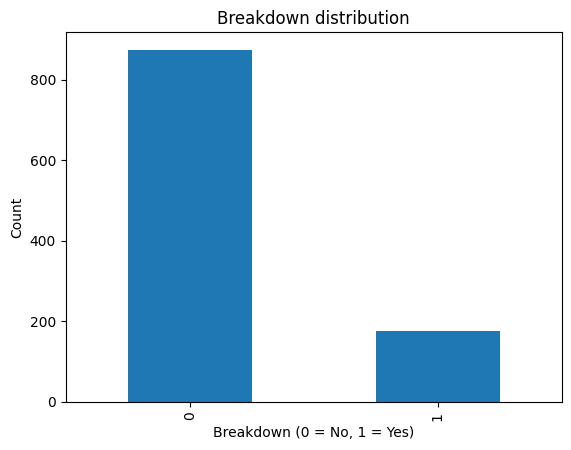

In [231]:
train["breakdown_next_30_days"].value_counts().plot(kind="bar")

plt.title("Breakdown distribution")
plt.xlabel("Breakdown (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

## Summary statistics

Next, we look at the numerical variables in the dataset.
This gives us an overview of the average values, minimum, maximum and spread of the features.

In [232]:
train.describe()

,id,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,cleanliness_score,driver_satisfaction_score,breakdown_next_30_days
count,1050.000000,1034.000000,1.033000e+03,1035.000000,1040.000000,1014.000000,1038.000000,995.000000,1037.000000,1050.000000
mean,742.984762,9.399420,3.639119e+06,4368.929467,10681.075986,60.682779,38.861387,69.393768,6.972183,0.167619
std,430.089010,5.752228,2.585818e+07,2214.510223,9341.969609,20.298624,47.968702,15.570872,1.478278,0.373706
min,0.000000,0.000000,-1.829042e+02,-50.000000,10.869020,0.000000,1.011100,-13.171570,2.504369,0.000000
25%,372.250000,5.000000,8.338616e+04,2773.353090,3374.773323,47.377582,8.187057,58.902723,6.001099,0.000000
50%,740.500000,9.000000,1.202357e+05,3967.125562,8085.318122,60.528422,16.788852,69.504547,6.928004,0.000000
75%,1109.250000,14.000000,1.674871e+05,5432.498224,14455.318280,74.654436,44.308719,79.597898,8.022503,0.000000
max,1498.000000,20.000000,3.734539e+08,10298.582128,40592.195120,102.548055,201.015553,144.139920,10.291940,1.000000


## Breakdown rate by vehicle brand

We group the data by `vehicle_brand` and calculate the average breakdown rate.
Because the target is binary, the mean of the target represents the breakdown rate.

In [233]:
brand_breakdown = train.groupby("vehicle_brand")["breakdown_next_30_days"].mean()
brand_breakdown.sort_values(ascending=False)

vehicle_brand
other         0.214286
Volvo         0.204301
Ford          0.190722
BMW           0.184000
Toyota        0.181347
Renault       0.164948
Volkswagen    0.139860
Kia           0.101449
Hyundai       0.099010
Name: breakdown_next_30_days, dtype: float64

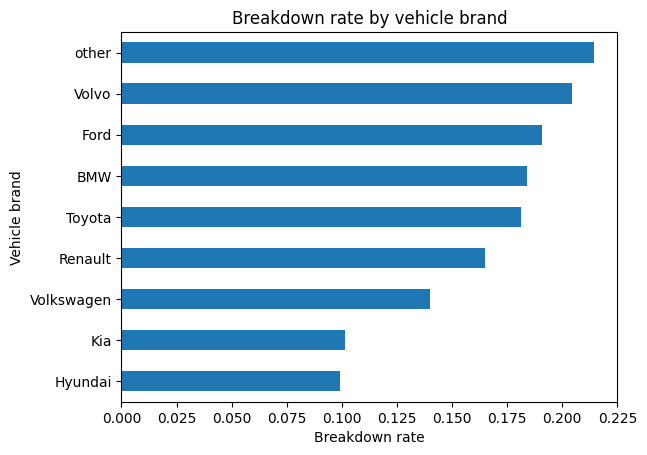

In [234]:
brand_breakdown.sort_values().plot(kind="barh")

plt.title("Breakdown rate by vehicle brand")
plt.xlabel("Breakdown rate")
plt.ylabel("Vehicle brand")
plt.show()

## Breakdown rate by fuel type

Different fuel types may have different breakdown patterns.
We therefore compare the average breakdown rate for each fuel type.

In [235]:
fuel_breakdown = train.groupby("fuel_type")["breakdown_next_30_days"].mean()
fuel_breakdown.sort_values(ascending=False)

fuel_type
electric    0.185185
petrol      0.174713
diesel      0.166667
hybrid      0.161290
other       0.150000
Name: breakdown_next_30_days, dtype: float64

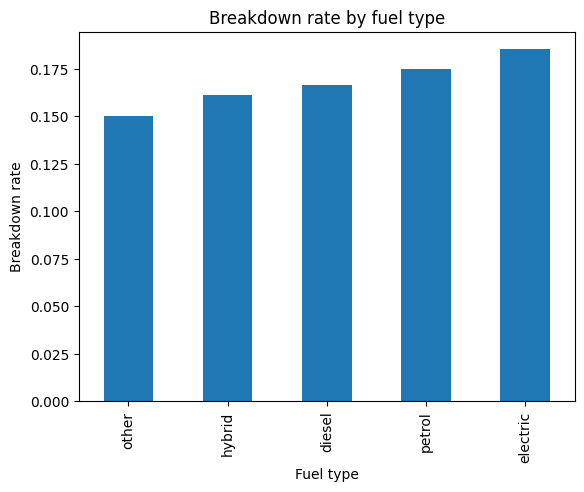

In [236]:
fuel_breakdown.sort_values().plot(kind="bar")

plt.title("Breakdown rate by fuel type")
plt.xlabel("Fuel type")
plt.ylabel("Breakdown rate")
plt.show()

## Breakdown rate by weather exposure

Weather exposure may affect the condition of a vehicle.
We analyse whether cars with higher exposure have a higher breakdown probability.

In [237]:
weather_breakdown = train.groupby("weather_exposure")["breakdown_next_30_days"].mean()
weather_breakdown.sort_values(ascending=False)

weather_exposure
high      0.200980
low       0.174479
medium    0.149533
other     0.142857
Name: breakdown_next_30_days, dtype: float64

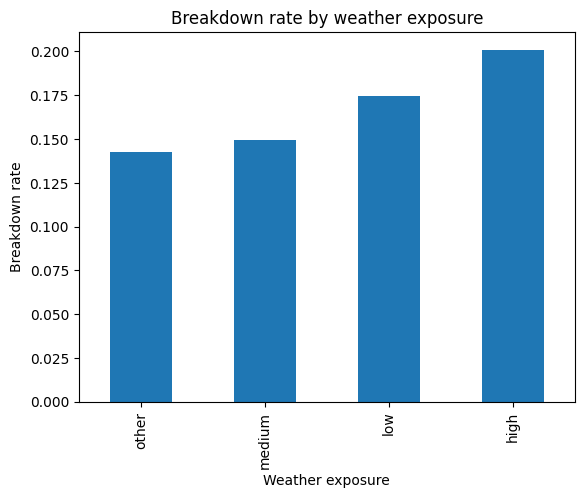

In [238]:
weather_breakdown.sort_values().plot(kind="bar")

plt.title("Breakdown rate by weather exposure")
plt.xlabel("Weather exposure")
plt.ylabel("Breakdown rate")
plt.show() 

## Breakdown rate by tyre type

Tyre type may also be related to vehicle condition and usage.

In [239]:
tyre_breakdown = train.groupby("tyre_type")["breakdown_next_30_days"].mean()
tyre_breakdown.sort_values(ascending=False)

tyre_type
all-season    0.204013
winter        0.162651
summer        0.150259
other         0.062500
Name: breakdown_next_30_days, dtype: float64

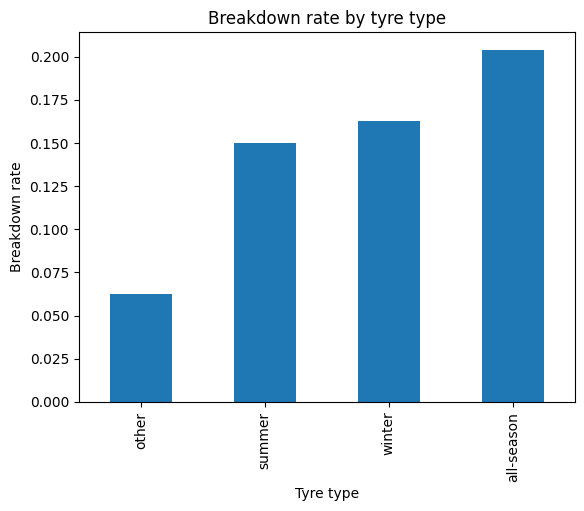

In [240]:
tyre_breakdown.sort_values().plot(kind="bar")

plt.title("Breakdown rate by tyre type")
plt.xlabel("Tyre type")
plt.ylabel("Breakdown rate")
plt.show()

## Mileage vs breakdown

We compare the mileage distribution for vehicles with and without breakdown.
A higher mileage can indicate more wear and tear.

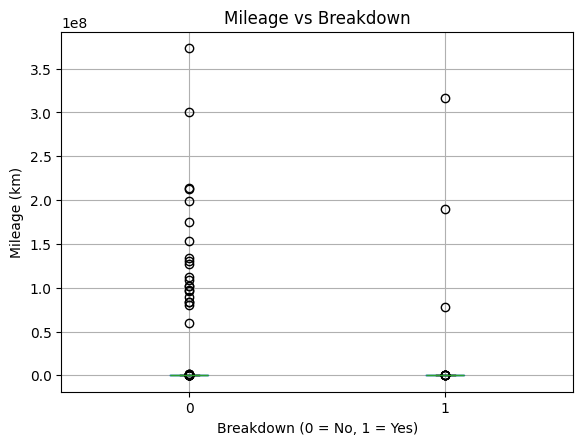

In [241]:
train.boxplot(column="mileage_km", by="breakdown_next_30_days")

plt.title("Mileage vs Breakdown")
plt.suptitle("")
plt.xlabel("Breakdown (0 = No, 1 = Yes)")
plt.ylabel("Mileage (km)")
plt.show()

## Oil quality vs breakdown

Oil quality is an important feature because it gives information about engine condition.
We compare the oil quality for the two classes.

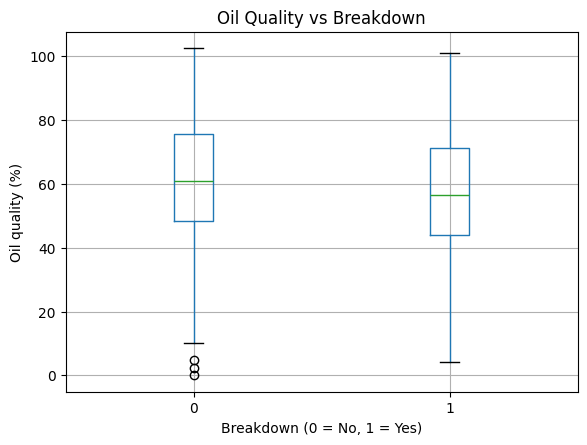

In [242]:
train.boxplot(column="oil_quality_pct", by="breakdown_next_30_days")

plt.title("Oil Quality vs Breakdown")
plt.suptitle("")
plt.xlabel("Breakdown (0 = No, 1 = Yes)")
plt.ylabel("Oil quality (%)")
plt.show()

## Last service distance vs breakdown

We also inspect the number of kilometers driven since the last service.
A larger distance since maintenance could increase the risk of breakdown.

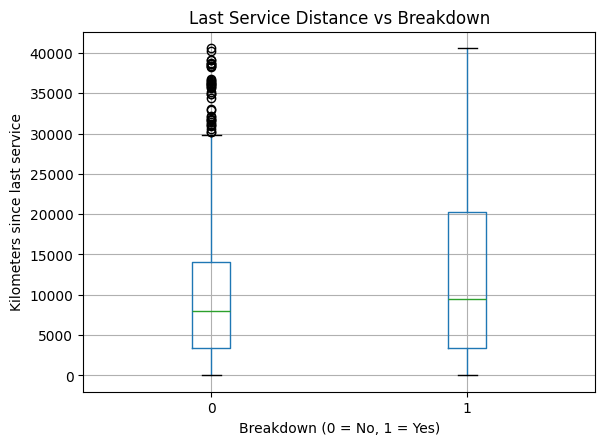

In [243]:
train.boxplot(column="last_service_km_ago", by="breakdown_next_30_days")

plt.title("Last Service Distance vs Breakdown")
plt.suptitle("")
plt.xlabel("Breakdown (0 = No, 1 = Yes)")
plt.ylabel("Kilometers since last service")
plt.show()

## Correlation analysis

We calculate the correlation matrix for the numerical variables.
This helps us see which numerical features may be related to the target and to each other.

In [244]:
correlation = train.corr(numeric_only=True)
correlation

,id,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,cleanliness_score,driver_satisfaction_score,breakdown_next_30_days
id,1.000000,-0.013399,-0.035830,-0.001577,0.018367,-0.036700,0.012493,0.003179,0.038817,-0.039711
vehicle_age_years,-0.013399,1.000000,-0.002210,0.015299,0.040071,0.016606,0.042474,0.025936,0.005639,0.138214
mileage_km,-0.035830,-0.002210,1.000000,0.114152,0.060717,0.036886,-0.034124,-0.027715,-0.055603,-0.003028
engine_hours,-0.001577,0.015299,0.114152,1.000000,-0.031101,0.022425,-0.031955,-0.013603,0.066042,0.053000
last_service_km_ago,0.018367,0.040071,0.060717,-0.031101,1.000000,0.043297,0.046232,0.008769,0.004347,0.067742
oil_quality_pct,-0.036700,0.016606,0.036886,0.022425,0.043297,1.000000,-0.012404,0.017318,-0.019642,-0.083499
avg_trip_length_km,0.012493,0.042474,-0.034124,-0.031955,0.046232,-0.012404,1.000000,0.019428,0.028570,-0.013303
cleanliness_score,0.003179,0.025936,-0.027715,-0.013603,0.008769,0.017318,0.019428,1.000000,-0.004824,-0.027467
driver_satisfaction_score,0.038817,0.005639,-0.055603,0.066042,0.004347,-0.019642,0.028570,-0.004824,1.000000,0.015899
breakdown_next_30_days,-0.039711,0.138214,-0.003028,0.053000,0.067742,-0.083499,-0.013303,-0.027467,0.015899,1.000000


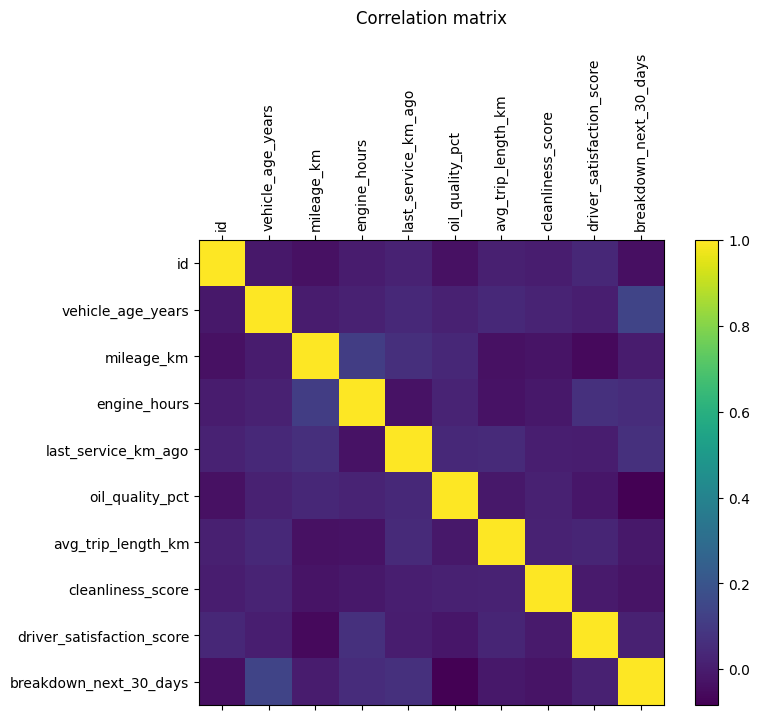

In [245]:
plt.figure(figsize=(8, 6))
plt.matshow(correlation, fignum=1)

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.colorbar()
plt.title("Correlation matrix", pad=20)
plt.show()

## EDA conclusion

From the exploratory data analysis we can make some first observations:

- The dataset contains both numerical and categorical variables.
- The target variable is imbalanced, because there are more cars without breakdown than with breakdown.
- Features such as mileage, oil quality and distance since last service seem relevant for predicting breakdowns.
- Some categorical variables such as vehicle brand, fuel type and weather exposure also show differences in breakdown rate.

These observations help us prepare the data for machine learning.

## Data preparation

We now prepare the dataset for machine learning.

We split the data into:
- `X`: the input features
- `y`: the target variable

Because machine learning models cannot directly work with text values, we convert the categorical variables using one-hot encoding.

In [246]:
X = train.drop(["id", "breakdown_next_30_days"], axis=1)
y = train["breakdown_next_30_days"]

X = pd.get_dummies(X)

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1050, 30)
Shape of y: (1050,)


## Train-validation split

To evaluate the model, we split the training data into a training set and a validation set.
We use 80% for training and 20% for validation.

In [247]:
X = train.drop(["id", "breakdown_next_30_days"], axis=1)
y = train["breakdown_next_30_days"]

X = pd.get_dummies(X)

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1050, 30)
Shape of y: (1050,)


## Random Forest baseline model

As required in the assignment, we use a Random Forest classifier as a baseline model.

Random Forest is a good first choice because:
- it can handle different types of features
- it works well for classification problems
- it is easy to use as a baseline

In [248]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (840, 30)
X_val shape: (210, 30)
y_train shape: (840,)
y_val shape: (210,)


In [249]:
model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42
)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## Model evaluation

We evaluate the Random Forest model on the validation set.

We use:
- accuracy
- confusion matrix

The confusion matrix gives more detailed insight into correct and incorrect predictions.

In [ ]:
val_probs = model.predict_proba(X_val)[:, 1]
val_predictions = (val_probs >= 0.6).astype(int)

print("Accuracy:", accuracy_score(y_val, val_predictions))
print()
print("Confusion matrix:")
print(confusion_matrix(y_val, val_predictions))

Accuracy: 0.8428571428571429

Confusion matrix:
[[171   4]
 [ 29   6]]


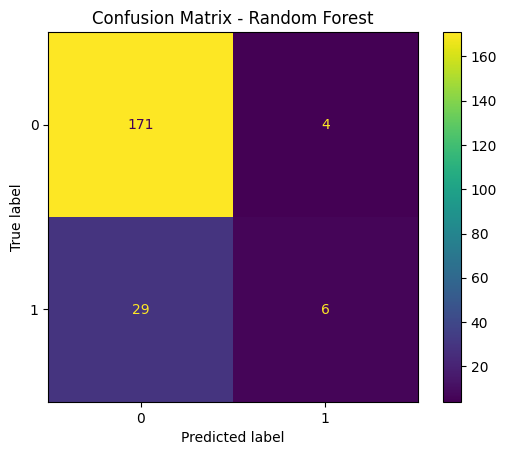

In [251]:
cm = confusion_matrix(y_val, val_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

## Evaluation conclusion

The Random Forest model gives us a first baseline result for this classification problem.

The confusion matrix helps us understand:
- how many vehicles were correctly predicted as no breakdown
- how many vehicles were correctly predicted as breakdown
- where the model makes mistakes

This baseline can later be improved by tuning parameters or testing other models.

## Load the test data

The test dataset does not contain the target variable.
We use the trained model to predict the breakdown outcome for these vehicles.

In [252]:
test = pd.read_csv("../test_CarBreakDown.csv")
test.head()

,id,vehicle_brand,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,weather_exposure,fuel_type,cleanliness_score,driver_satisfaction_score,tyre_type
0,1356,Volkswagen,11.0,227101.296523,7111.496798,31877.398870,45.316195,11.303376,medium,petrol,86.002184,6.789866,winter
1,889,Kia,5.0,131740.074640,4384.690626,24086.715660,55.920468,21.079253,high,petrol,99.964621,9.780574,winter
2,1190,Hyundai,20.0,172283.708707,5997.321760,1087.406667,69.344516,2.827233,medium,diesel,NaN,6.525088,summer
3,122,Toyota,14.0,125092.331956,3710.026613,6919.769411,55.607730,15.947450,NaN,diesel,82.986605,5.850790,all-season
4,1101,Ford,19.0,207068.220620,7152.178785,8102.143623,78.170298,31.696566,low,electric,92.119900,7.954186,summer


## Prepare the test data

We keep the `id` column separately because it is needed in the submission file.
The `id` column is not used as an input feature for the model.

We then apply the same preprocessing as for the training data.

In [253]:
test_ids = test["id"]

test_features = test.drop("id", axis=1)
test_features = pd.get_dummies(test_features)
test_features = test_features.reindex(columns=X.columns, fill_value=0)

print("Shape of test features:", test_features.shape)

Shape of test features: (450, 30)


## Make predictions on the test set

In [254]:
test_probs = model.predict_proba(test_features)[:, 1]
test_predictions = (test_probs >= 0.43).astype(int)

## Create the submission file

The final submission file must contain:
- `id`
- `breakdown_next_30_days`

This file can be uploaded to Kaggle.

In [255]:
submission = pd.DataFrame({
    "id": test_ids,
    "breakdown_next_30_days": test_predictions
})

submission.head()

,id,breakdown_next_30_days
0,1356,0
1,889,0
2,1190,0
3,122,0
4,1101,0


In [256]:
submission.to_csv("submission.csv", index=False)
print("submission.csv has been created.")

submission.csv has been created.


## Final conclusion

In this notebook we first explored the training data and then built a Random Forest baseline model.

Main steps:
- analysed the dataset using EDA
- checked the target distribution
- explored several numerical and categorical variables
- prepared the data for machine learning
- trained a Random Forest classifier
- evaluated the model using accuracy and a confusion matrix
- generated predictions for the test dataset
- created a submission file for Kaggle

This notebook gives a clear baseline for the car breakdown prediction challenge.

## GenAI section

GenAI was used as a support tool during this project.

It was used to:
- help structure the notebook
- suggest a logical EDA workflow
- explain how to build a simple Random Forest baseline
- help with the creation of the submission file

All choices in this notebook were reviewed and understood before being included.
The final decisions about analysis, preprocessing and modeling were made by the student.